<a href="https://colab.research.google.com/github/belgaa-a/EksploracjaDanych/blob/main/AW_zajecia3_2210.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorium 3 — Otwarte dane i wartości odstające

**Eksploracja danych** · dr Paweł Gliwny · WFiIS UŁ

Na tych zajęciach:

1. **Część 1** — pobierzesz dane z portalu otwartych danych Łodzi, wczytasz je, zmienisz ich format, policzysz statystyki zbiorcze i zrobisz proste wykresy.
2. **Część 2** — na danych o pacjentach przejdziesz kolejne kroki wykrywania wartości odstających: od najprostszych do bardziej złożonych.

Miejsca do uzupełnienia oznaczone są `# TODO`. Odpowiedzi na pytania wpisuj w komórkach tekstowych oznaczonych ✍️.

> Notatnik po zajęciach umieść w swoim repozytorium na GitHubie.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.float_format", "{:.2f}".format)
plt.rcParams["figure.dpi"] = 100

In [3]:
def upewnij_sie_ze_jest(nazwa_pliku):
    # W Colabie: jeśli pliku nie ma, otwiera okno wgrywania pliku.
    if Path(nazwa_pliku).exists():
        print(f"Plik {nazwa_pliku} jest na miejscu.")
        return
    try:
        from google.colab import files
        print(f"Wgraj plik {nazwa_pliku}:")
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Umieść plik {nazwa_pliku} w folderze z notatnikiem.")

---
# Część 1. Dane z portalu otwartych danych Łodzi

Portal: [otwarte.miasto.lodz.pl](https://otwarte.miasto.lodz.pl)

Zaczynamy od wspólnego przykładu — pliku `szkolnictwo_wysze.csv` (szkolnictwo wyższe w Łodzi w latach 2012–2024). Pobierz go z portalu albo od prowadzącego i wgraj do Colaba (ikona folderu po lewej lub komórka poniżej).

In [4]:
PLIK_LODZ = "szkolnictwo_wysze.csv"
upewnij_sie_ze_jest(PLIK_LODZ)

Wgraj plik szkolnictwo_wysze.csv:


Saving szkolnictwo_wysze.csv to szkolnictwo_wysze.csv


## 1.1 Wczytanie danych

Zanim wywołasz `read_csv`, obejrzyj surowy plik — pierwsze linie tekstu powiedzą, jaki jest separator.

In [5]:
# podgląd surowego pliku
with open(PLIK_LODZ, encoding="utf-8") as f:
    for _ in range(5):
        print(f.readline().rstrip())

﻿name;rok;wartość;zmienna
Szkolnictwo wyższe;2012;22;uczelnie
Szkolnictwo wyższe;2013;22;uczelnie
Szkolnictwo wyższe;2014;23;uczelnie
Szkolnictwo wyższe;2015;21;uczelnie


In [7]:
# TODO: wczytaj plik do ramki `df` z właściwym separatorem
df = pd.read_csv(PLIK_LODZ, sep=";", encoding="utf-8-sig")
display(df.head())
# TODO: wyświetl pierwsze wiersze, wymiary i typy kolumn
print("Wymiary:", df.shape)
print(df.dtypes)

,name,rok,wartość,zmienna
0,Szkolnictwo wyższe,2012,22,uczelnie
1,Szkolnictwo wyższe,2013,22,uczelnie
2,Szkolnictwo wyższe,2014,23,uczelnie
3,Szkolnictwo wyższe,2015,21,uczelnie
4,Szkolnictwo wyższe,2016,20,uczelnie


Wymiary: (65, 4)
name       object
rok         int64
wartość     int64
zmienna    object
dtype: object


✍️ **Pytanie:** Jaki jest separator? Czy kolumna `wartość` ma typ liczbowy? Czy nazwy kolumn z polskimi znakami wczytały się poprawnie?

*Odpowiedź:* …

## 1.2 Format długi czy szeroki?

Przypomnienie z wykładu 2: w formacie **długim** każdy wiersz to jedna para (zmienna, wartość); w formacie **szerokim** każda zmienna ma własną kolumnę.

1. Sprawdź, jakie wartości przyjmuje kolumna `zmienna` i ile razy każda występuje.
2. Przekształć dane do formatu szerokiego: wiersze = lata, kolumny = zmienne.

In [11]:
# TODO: jakie są zmienne i ile mają wierszy?
print("Zmienne:", df["zmienna"].unique())
print("Liczba wierszy:", len(df))

# TODO: format szeroki (pivot) — wynik zapisz w `szeroka`
szeroka = df.pivot(index="rok", columns="zmienna", values="wartość")
szeroka

Zmienne: ['uczelnie' 'ogółem' 'kobiety' 'mężczyźni' 'absolwenci ogółem']
Liczba wierszy: 65


zmienna,absolwenci ogółem,kobiety,mężczyźni,ogółem,uczelnie
rok,,,,,
2012,24825,55265,36281,91546,22
2013,22590,50007,33464,83471,22
2014,21343,48220,32456,80676,23
2015,19835,45584,30769,76353,21
2016,17662,44053,29908,73961,20
2017,19281,42990,29029,72019,22
2018,17046,39312,26253,65565,20
2019,15819,38146,26297,64443,19
2020,14082,39170,26155,65325,18


## 1.3 Czy dane są spójne?

Liczba studentów `ogółem` powinna być sumą `kobiety` i `mężczyźni`. Sprawdź to dla każdego roku.

In [12]:
# TODO: policz różnicę (kobiety + mężczyźni) − ogółem dla każdego roku
roznica = szeroka["kobiety"] + szeroka["mężczyźni"] - szeroka["ogółem"]
display(roznica.rename("różnica"))
print("Czy suma jest zgodna w każdym roku?", roznica.eq(0).all())


,różnica
rok,
2012,0
2013,0
2014,0
2015,0
2016,0
2017,0
2018,0
2019,0
2020,0


Czy suma jest zgodna w każdym roku? True


## 1.4 Statystyki zbiorcze

1. Policz statystyki opisowe dla wszystkich zmiennych (`describe`).
2. O ile procent zmieniła się każda zmienna między 2012 a 2024 rokiem?
3. Dodaj kolumnę `udzial_kobiet` (udział kobiet wśród studentów) i kolumnę `studenci_na_uczelnie`.

In [13]:
# TODO: statystyki opisowe
display(szeroka.describe())

# TODO: zmiana procentowa 2012 → 2024
zmiana_proc = (szeroka.loc[2024] - szeroka.loc[2012]) / szeroka.loc[2012] * 100
display(zmiana_proc.rename("zmiana procentowa 2012–2024"))

# TODO: nowe kolumny
szeroka["udział_kobiet"] = szeroka["kobiety"] / szeroka["ogółem"] * 100
szeroka["udział_mężczyzn"] = szeroka["mężczyźni"] / szeroka["ogółem"] * 100


zmienna,absolwenci ogółem,kobiety,mężczyźni,ogółem,uczelnie
count,13.00,13.00,13.00,13.00,13.00
mean,17780.54,43010.92,28793.92,71804.85,19.54
std,3522.40,5391.05,3524.63,8900.65,2.44
min,14082.00,38146.00,25710.00,64272.00,15.00
25%,14756.00,39170.00,26049.00,65297.00,18.00
50%,17046.00,39958.00,26297.00,66002.00,20.00
75%,19835.00,45584.00,30769.00,76353.00,22.00
max,24825.00,55265.00,36281.00,91546.00,23.00


,zmiana procentowa 2012–2024
zmienna,
absolwenci ogółem,-41.29
kobiety,-30.22
mężczyźni,-29.14
ogółem,-29.79
uczelnie,-31.82


## 1.5 Wykresy

Narysuj trzy wykresy (najlepiej obok siebie, `plt.subplots(1, 3)`):

1. liczba studentów w czasie — osobne linie dla kobiet i mężczyzn,
2. liczba uczelni w czasie,
3. udział kobiet wśród studentów (oś Y od 0 do 1).

Każdy wykres podpisz: tytuł, opisy osi.

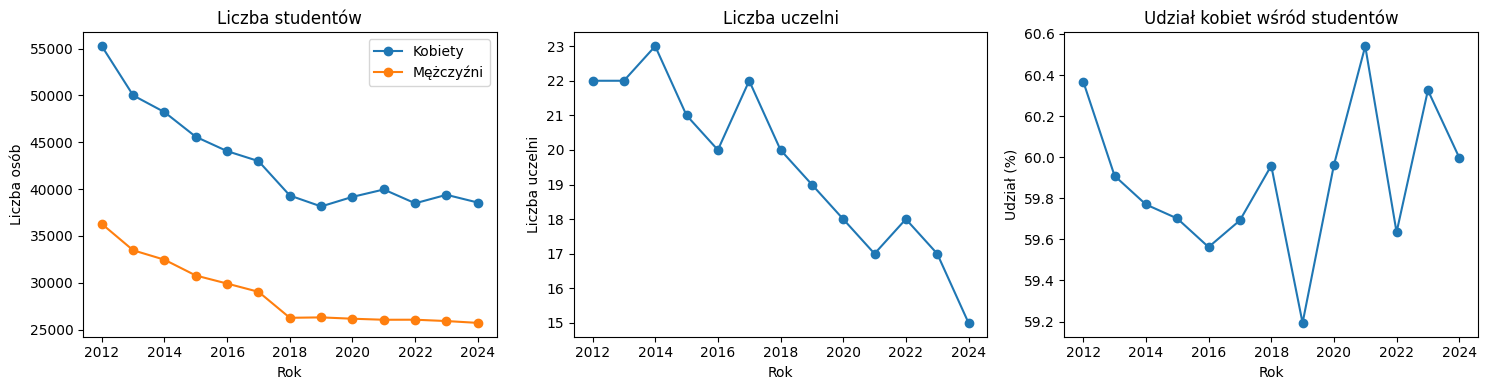

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# TODO: wykres 1 — kobiety i mężczyźni
szeroka[["kobiety", "mężczyźni"]].plot(ax=axes[0], marker="o")
axes[0].set_title("Liczba studentów")
axes[0].set_xlabel("Rok")
axes[0].set_ylabel("Liczba osób")
axes[0].legend(["Kobiety", "Mężczyźni"])

# TODO: wykres 2 — uczelnie
szeroka["uczelnie"].plot(ax=axes[1], marker="o")
axes[1].set_title("Liczba uczelni")
axes[1].set_xlabel("Rok")
axes[1].set_ylabel("Liczba uczelni")

# TODO: wykres 3 — udział kobiet
szeroka["udział_kobiet"].plot(ax=axes[2], marker="o")
axes[2].set_title("Udział kobiet wśród studentów")
axes[2].set_xlabel("Rok")
axes[2].set_ylabel("Udział (%)")

plt.tight_layout()
plt.show()

✍️ **Wnioski** (3 zdania): co się stało ze szkolnictwem wyższym w Łodzi w latach 2012–2024?

*Odpowiedź:*

Liczba studentów na przestrzeni tych lat wyraźnie spadła, w ostatnich latach spadek był mniejszy.
Liczba uczelni zmniejszyła się z 22 do 15. Udział kobiet stanowił większą część studentów niż mężczyźni.

## 1.6 Zadanie samodzielne: Twój zbiór z portalu Łodzi

Wybierz **inny** zbiór z [otwarte.miasto.lodz.pl](https://otwarte.miasto.lodz.pl) i przejdź te same kroki:

1. Podaj nazwę zbioru, link i datę pobrania.
2. Wczytaj plik (separator? kodowanie? przecinek dziesiętny?).
3. Ustal, czy dane są w formacie długim, czy szerokim; w razie potrzeby przekształć.
4. Sprawdź braki (`isna().sum()`) i spójność danych.
5. Policz statystyki zbiorcze.
6. Zrób 2–3 podpisane wykresy i napisz 2–3 zdania wniosków.

✍️ **Zbiór:** rejestr-zabytkow.csv · **link:** https://otwarte.miasto.lodz.pl/zabytki/ · **data pobrania:** 22.10.2026

In [17]:
# TODO: wczytanie i przegląd Twojego zbioru
PLIK_ZABYTKI = "rejestr-zabytkow.csv"
upewnij_sie_ze_jest(PLIK_ZABYTKI)

df = pd.read_csv(PLIK_ZABYTKI, sep=";", encoding="utf-8-sig")

df.columns = ["Lp", "Ulica", "Numer_porządkowy", "Nazwa_obiektu", "Nr_rejestru_zabytków"]
df["Ulica"] = df["Ulica"].astype("string").str.strip()
df["Numer_porządkowy"] = df["Numer_porządkowy"].astype("string").str.strip()
df["Nazwa_obiektu"] = (
    df["Nazwa_obiektu"].astype("string")
    .str.replace(r"\\s+", " ", regex=True).str.strip()
)

print("Wymiary zbioru:", df.shape)
display(df.head())
print("\\nTypy danych:")
display(df.dtypes)
print("\\nLiczba braków:")
display(df.isna().sum())
print("\\nLiczba unikalnych ulic:", df["Ulica"].nunique())
print("Liczba unikalnych nazw obiektów:", df["Nazwa_obiektu"].nunique())
print("Liczba całkowicie zduplikowanych wierszy:", df.duplicated().sum())
print("Liczba powtarzających się adresów (ulica + numer):",
      df.duplicated(["Ulica", "Numer_porządkowy"]).sum())

Plik rejestr-zabytkow.csv jest na miejscu.
Wymiary zbioru: (2769, 5)


,Lp,Ulica,Numer_porządkowy,Nazwa_obiektu,Nr_rejestru_zabytków
0,1,Abramowskiego,1,Kamienica (budynek frontowy),NaN
1,2,Abramowskiego,3,Kamienica (budynek frontowy),NaN
2,3,Abramowskiego,7,Kamienica (budynek frontowy),NaN
3,4,Abramowskiego,14,Kamienica (budynek frontowy),NaN
4,5,Abramowskiego,16,Kamienica (budynek frontowy),NaN


\nTypy danych:


,0
Lp,int64
Ulica,string[python]
Numer_porządkowy,string[python]
Nazwa_obiektu,string[python]
Nr_rejestru_zabytków,object


\nLiczba braków:


,0
Lp,0
Ulica,0
Numer_porządkowy,13
Nazwa_obiektu,0
Nr_rejestru_zabytków,2240


\nLiczba unikalnych ulic: 339
Liczba unikalnych nazw obiektów: 1503
Liczba całkowicie zduplikowanych wierszy: 0
Liczba powtarzających się adresów (ulica + numer): 141


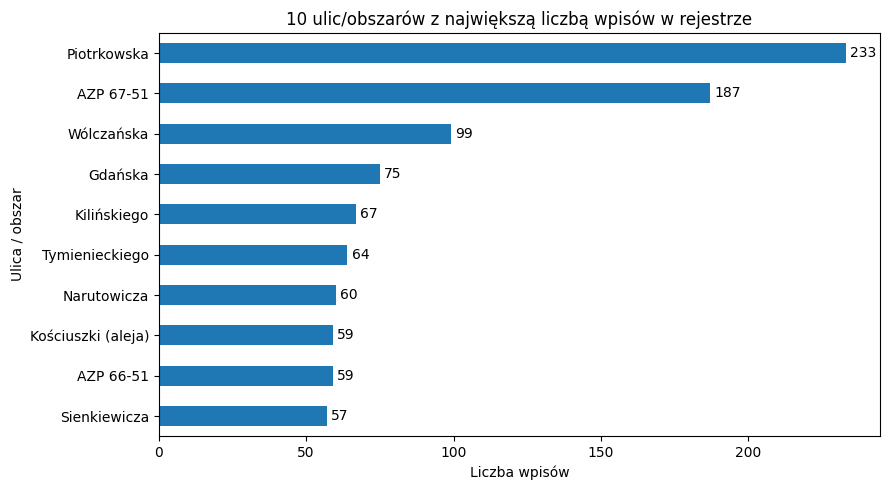

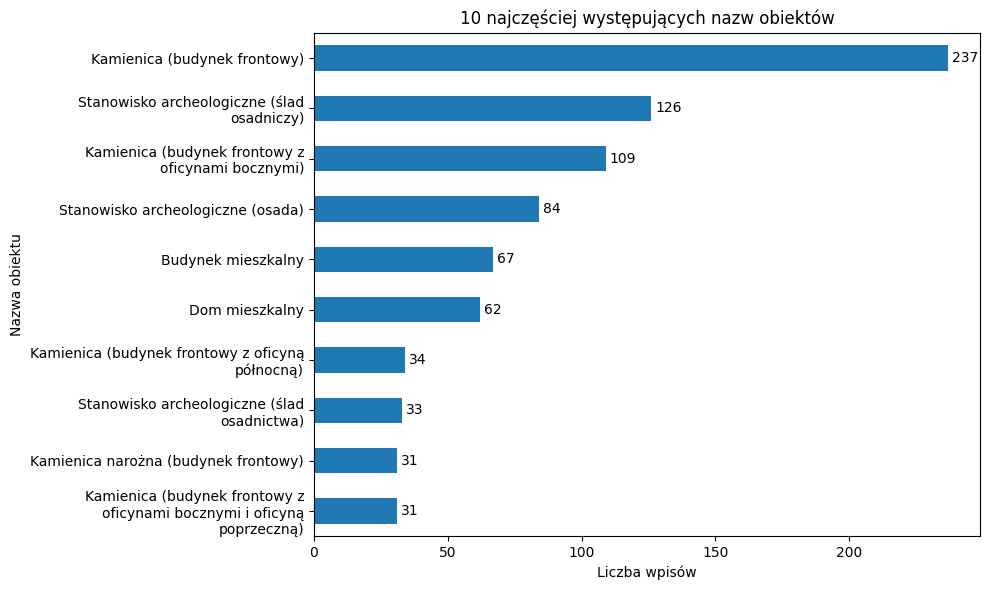

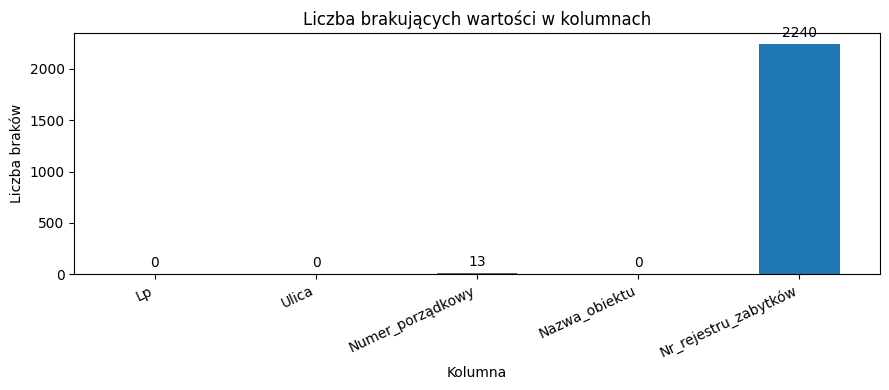

In [20]:
# TODO: przekształcenia, statystyki i wykresy
# Wykres 1. Ulice z największą liczbą wpisów
top_ulice = df["Ulica"].value_counts().head(10).sort_values()
ax = top_ulice.plot(kind="barh", figsize=(9, 5))
ax.bar_label(ax.containers[0], padding=3, fmt="%d")
plt.title("10 ulic/obszarów z największą liczbą wpisów w rejestrze")
plt.xlabel("Liczba wpisów")
plt.ylabel("Ulica / obszar")
plt.tight_layout()
plt.show()

# Wykres 2. Najczęściej występujące nazwy obiektów
top_obiekty = df["Nazwa_obiektu"].value_counts().head(10).sort_values()
ax = top_obiekty.plot(kind="barh", figsize=(10, 6))
ax.bar_label(ax.containers[0], padding=3, fmt="%d")
plt.title("10 najczęściej występujących nazw obiektów")
plt.xlabel("Liczba wpisów")
plt.ylabel("Nazwa obiektu")
plt.tight_layout()
plt.show()

# Wykres 3. Braki danych w kolumnach
braki = df.isna().sum()
ax = braki.plot(kind="bar", figsize=(9, 4))
ax.bar_label(ax.containers[0], padding=3, fmt="%d")
plt.title("Liczba brakujących wartości w kolumnach")
plt.xlabel("Kolumna")
plt.ylabel("Liczba braków")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

✍️ **Wnioski:**

1. Zbiór zawiera 2769 wpisów, 339 różnych ulic/obszarów i 1502 różne nazwy obiektów. Najwięcej wpisów przypada na ulicę Piotrkowską (233), a kolejne często występujące wartości to oznaczenia obszarów archeologicznych.
2. Najczęściej występującą nazwą obiektu jest „Kamienica (budynek frontowy)” (237 wpisów). W danych występują też liczne stanowiska archeologiczne, więc rejestr obejmuje różne rodzaje zabytków.
3. W kolumnie numeru porządkowego brakuje 13 wartości, a w kolumnie numeru rejestru zabytków aż 2240. Nie ma całkowicie identycznych wierszy, ale 141 adresów (ulica + numer) się powtarza — nie musi to oznaczać błędu, ponieważ pod jednym adresem może być więcej niż jeden wpis lub obiekt. Przed analizą kolumnę z numerem rejestru należy sprawdzić pod kątem struktury źródłowego pliku.

---
# Część 2. Wartości odstające — dane o pacjentach

Zbiór: 3000 pacjentów z kolumnami `age` (wiek), `bmi`, `avg_glucose_level` (średni poziom glukozy we krwi, mg/dl), `hypertension`, `heart_disease`, `work_type` (rodzaj pracy), `smoking_status` (palenie), `stroke` (udar: 1/0) i kilkoma innymi.

> ⚠️ To **dane syntetyczne** — wygenerowane i celowo „zepsute” do ćwiczeń. Nie wyciągamy z nich wniosków medycznych.
>
> Źródło: deepsense.ai, *EDA Benchmark*, zadanie `identify-unusual-values` ([github.com/deepsense-ai/eda-benchmark](https://github.com/deepsense-ai/eda-benchmark)), licencja CC BY-NC-ND 4.0.

Plan — od najprostszej metody do najbardziej złożonej:

| Krok | Metoda |
|---|---|
| 1 | wartości niemożliwe — progi z wiedzy dziedzinowej |
| 2 | wartości skrajne w jednej zmiennej — wykresy, potem IQR, z-score, MAD |
| 3 | nielogiczne kombinacje kategorii — reguły |
| 4 | nietypowe kombinacje liczb — odległość od środka |
| 5 | decyzja: co zrobić z każdą grupą |

In [21]:
URL = ("https://raw.githubusercontent.com/deepsense-ai/eda-benchmark/main/"
       "tasks/identify-unusual-values/environment/dataset/synthetic_stroke_data.csv")

pacjenci = pd.read_csv(URL)
oryginal = pacjenci.copy()      # kopia surowych danych — przyda się na końcu
pacjenci.head()

,patient_id,gender,age,hypertension,heart_disease,ever_married,work_type,residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,A456281,Male,25.00,0,0,False,student,Urban,77.47,35.66,formerly smoked,0
1,A730553,Male,16.00,0,0,True,student,Urban,83.78,34.76,never smoked,0
2,A800980,Male,19.00,0,0,True,Private,Urban,91.65,25.38,never smoked,0
3,A433166,Male,35.00,0,0,True,Self-employed,Urban,97.09,21.26,never smoked,0
4,A114521,Male,15.00,0,0,True,student,Urban,89.17,22.27,formerly smoked,0


## 2.0 Pierwszy rzut oka

Wyświetl statystyki opisowe kolumn liczbowych `age`, `bmi`, `avg_glucose_level` i narysuj ich histogramy.

,age,bmi,avg_glucose_level
count,3000.00,3000.00,3000.00
mean,45.25,26.29,134.00
std,20.83,15.88,181.27
min,0.67,-5.20,-21.40
25%,28.00,21.28,85.59
50%,49.00,24.70,101.40
75%,63.00,28.88,127.43
max,80.00,105.60,1254.60


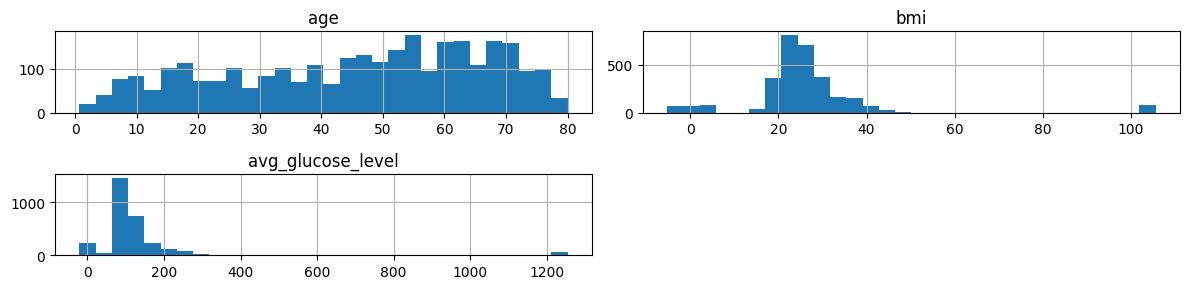

In [23]:
LICZBOWE = ["age", "bmi", "avg_glucose_level"]

# TODO: statystyki opisowe
display(pacjenci[LICZBOWE].describe())

# TODO: histogramy (np. pacjenci[LICZBOWE].hist(...))
pacjenci[LICZBOWE].hist(figsize=(12, 3), bins=30)
plt.tight_layout()
plt.show()

✍️ **Pytanie:** Które wartości minimalne i maksymalne są w ogóle *możliwe* u człowieka?

*Odpowiedź:*

Wiek człowieka powinien mieścić się w zakresie 0–120 lat, BMI musi być dodatnie i typowo przyjmuje wartości znacznie poniżej 60, a poziom glukozy we krwi nie może być ujemny

## 2.1 Krok 1: wartości niemożliwe

Przyjmujemy progi:

| Zmienna | Zakres możliwy |
|---|---|
| `bmi` | 10–60 |
| `avg_glucose_level` | 20–800 mg/dl |
| `age` | 0–120 lat |

Wartości spoza zakresu to **szum techniczny**, a nie rzadcy pacjenci — zamieniamy je na `NaN`.

1. Utwórz maski `zle_bmi`, `zla_glukoza`, `zly_wiek` (przyda się `Series.between`).
2. Policz, ile wartości jest niemożliwych w każdej kolumnie i ilu pacjentów ma co najmniej jedną taką wartość.
3. Zamień niemożliwe wartości na `NaN`.

In [24]:
# TODO: maski
zle_bmi = ~pacjenci["bmi"].between(10, 60)
zla_glukoza = ~pacjenci["avg_glucose_level"].between(20, 800)
zly_wiek = ~pacjenci["age"].between(0, 120)

# TODO: liczebności
print("Nieprawidłowe BMI:", int(zle_bmi.sum()))
print("Nieprawidłowa glukoza:", int(zla_glukoza.sum()))
print("Nieprawidłowy wiek:", int(zly_wiek.sum()))
print("Pacjenci z co najmniej jedną niemożliwą wartością:",
      int((zle_bmi | zla_glukoza | zly_wiek).sum()))

# TODO: zamiana na NaN
pacjenci.loc[zle_bmi, "bmi"] = np.nan
pacjenci.loc[zla_glukoza, "avg_glucose_level"] = np.nan
pacjenci.loc[zly_wiek, "age"] = np.nan


Nieprawidłowe BMI: 300
Nieprawidłowa glukoza: 300
Nieprawidłowy wiek: 0
Pacjenci z co najmniej jedną niemożliwą wartością: 560


,age,bmi,avg_glucose_level
count,3000.00,2700.00,2700.00
mean,45.25,26.12,116.84
std,20.83,5.84,44.45
min,0.67,13.57,44.76
25%,28.00,21.94,89.47
50%,49.00,24.98,103.09
75%,63.00,28.85,127.84
max,80.00,47.62,332.91


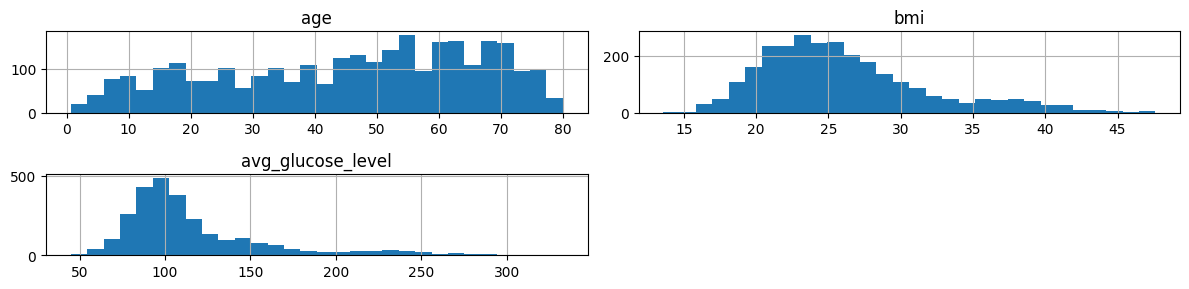

In [25]:
# TODO: ponownie statystyki opisowe i histogramy — co się zmieniło?
display(pacjenci[LICZBOWE].describe())
pacjenci[LICZBOWE].hist(figsize=(12, 3), bins=30)
plt.tight_layout()
plt.show()


## 2.2 Krok 2a: wartości skrajne w jednej zmiennej — wykresy

Zanim cokolwiek policzysz, **obejrzyj** dane.

1. Narysuj obok siebie poziome wykresy pudełkowe dla `bmi` i `avg_glucose_level` (`plt.subplots(1, 2)`, `ax.boxplot(..., orientation="horizontal")`). Pamiętaj o `dropna()`.
2. Narysuj obok siebie dwa wykresy punktowe: `age` × `avg_glucose_level` i `age` × `bmi`.

Podpisz osie (z jednostkami) i nadaj tytuły.

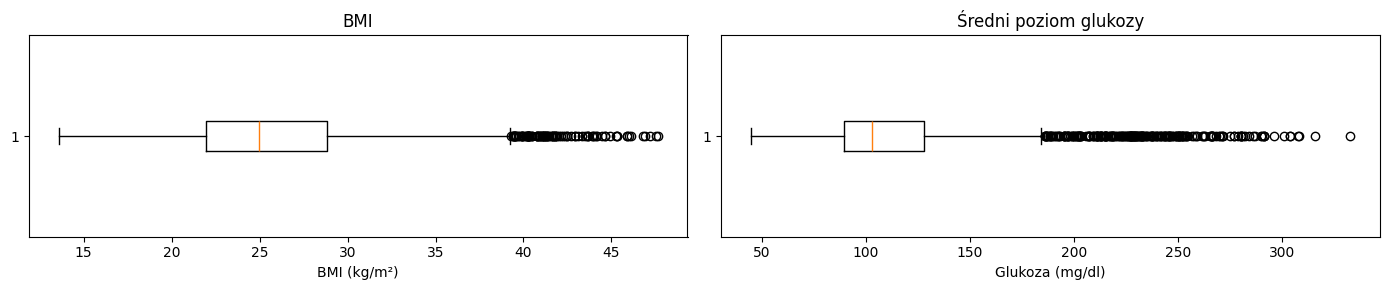

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3))

# TODO: wykresy pudełkowe bmi i glukozy
axes[0].boxplot(pacjenci["bmi"].dropna(), orientation="horizontal")
axes[0].set_title("BMI")
axes[0].set_xlabel("BMI (kg/m²)")
axes[1].boxplot(pacjenci["avg_glucose_level"].dropna(), orientation="horizontal")
axes[1].set_title("Średni poziom glukozy")
axes[1].set_xlabel("Glukoza (mg/dl)")

plt.tight_layout()
plt.show()

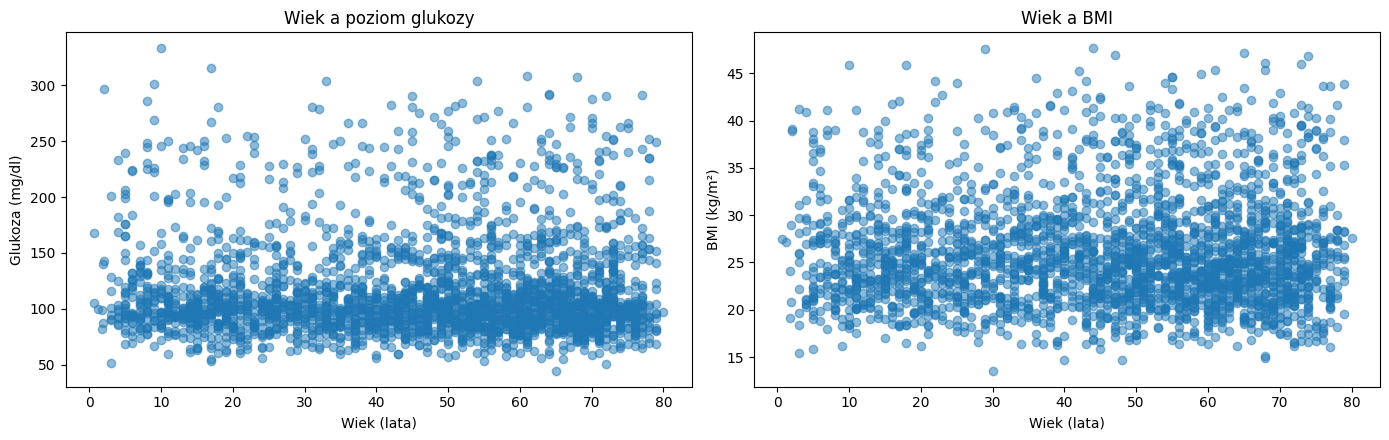

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# TODO: wykresy punktowe age × glukoza i age × bmi
axes[0].scatter(pacjenci["age"], pacjenci["avg_glucose_level"], alpha=0.5)
axes[0].set_title("Wiek a poziom glukozy")
axes[0].set_xlabel("Wiek (lata)")
axes[0].set_ylabel("Glukoza (mg/dl)")
axes[1].scatter(pacjenci["age"], pacjenci["bmi"], alpha=0.5)
axes[1].set_title("Wiek a BMI")
axes[1].set_xlabel("Wiek (lata)")
axes[1].set_ylabel("BMI (kg/m²)")

plt.tight_layout()
plt.show()

✍️ **Pytania:**
1. Dla której zmiennej jest więcej punktów poza wąsami? Czy leżą po obu stronach pudełka, czy tylko po jednej?
2. Na wykresie punktowym: czy wysokie wartości glukozy występują tylko w określonym wieku? Czy 10-latek ze średnią glukozą ponad 300 mg/dl to błąd, czy rzadki przypadek?

*Odpowiedź:*
1. Liczba punktów poza wąsami zależy od rozkładu.
dla silnie prawoskośnej glukozy odstające punkty występują przede wszystkim po stronie wysokich wartości
2. Wysoka glukoza może wystąpić w różnych grupach wieku, a wynik ponad 300 mg/dl u 10-latka jest nietypowy, ale nie musi być błędem

## 2.3 Krok 2b: wartości skrajne w jednej zmiennej — metody liczbowe

Napisz trzy funkcje, które dla kolumny `s` zwracają maskę (`True` = wartość odstająca):

- `maska_iqr(s, k=1.5)` — poza $[Q_1 - k \cdot IQR,\; Q_3 + k \cdot IQR]$,
- `maska_z(s, prog=3)` — $|z| > prog$, gdzie $z = (x - \bar{x}) / s$,
- `maska_mad(s, prog=3.5)` — odporny z-score $|0{,}6745 \cdot (x - \text{med}) / \text{MAD}| > prog$.

Braki (`NaN`) nie powinny być oznaczane jako odstające.

In [29]:
def maska_iqr(s, k=1.5):
    # TODO
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - k * iqr) | (s > q3 + k * iqr)).fillna(False)

def maska_z(s, prog=3):
    # TODO
    z = (s - s.mean()) / s.std()
    return (z.abs() > prog).fillna(False)

def maska_mad(s, prog=3.5):
    # TODO
    med = s.median()
    mad = (s - med).abs().median()
    if pd.isna(mad) or mad == 0:
        return pd.Series(False, index=s.index)
    z_robust = 0.6745 * (s - med) / mad
    return (z_robust.abs() > prog).fillna(False)

Zbuduj tabelę porównawczą: wiersze = zmienne (`age`, `bmi`, `avg_glucose_level`), kolumny = metody (IQR 1,5, IQR 3, z-score, MAD), wartości = liczba wykrytych obserwacji. Dodaj kolumnę ze **skośnością** (`skew`).

In [30]:
# TODO: tabela porównawcza `porownanie`
kolumny = ["age", "bmi", "avg_glucose_level"]
porownanie = pd.DataFrame(index=kolumny)
porownanie["IQR 1,5"] = [maska_iqr(pacjenci[c], 1.5).sum() for c in kolumny]
porownanie["IQR 3"] = [maska_iqr(pacjenci[c], 3).sum() for c in kolumny]
porownanie["z-score"] = [maska_z(pacjenci[c]).sum() for c in kolumny]
porownanie["MAD"] = [maska_mad(pacjenci[c]).sum() for c in kolumny]
porownanie["skośność"] = [pacjenci[c].skew() for c in kolumny]
porownanie


,"IQR 1,5",IQR 3,z-score,MAD,skośność
age,0,0,0,0,-0.33
bmi,100,0,23,33,0.99
avg_glucose_level,235,81,62,223,1.80


✍️ **Pytanie:** Dlaczego dla glukozy metody dają tak różne wyniki, a dla wieku żadna nic nie wykrywa? Spójrz na skośność i histogramy.

*Odpowiedź:*

Rozkład glukozy jest silnie prawoskośny i ma długi ogon, dlatego metody różnie reagują na wysokie wartości:
- z-score zależy od średniej i odchylenia standardowego
- IQR i MAD korzystają z miar odporniejszych na skrajności.

Wiek ma ograniczony zakres i w tym zbiorze nie zawiera obserwacji wystarczająco oddalonych od środka, by przekroczyć przyjęte progi.

### Wykres: zaznacz wartości odstające

Powtórz wykres punktowy `age` × `avg_glucose_level`, ale tym razem:

- zaznacz innym kolorem pacjentów, których glukoza jest odstająca według `maska_iqr` (i podaj ich liczbę w legendzie),
- narysuj poziomą linię przerywaną na górnej granicy $Q_3 + 1{,}5 \cdot IQR$ (`ax.axhline`).

Sprawdź: czy liczba punktów nad linią zgadza się z liczbą punktów poza wąsem na wykresie pudełkowym?

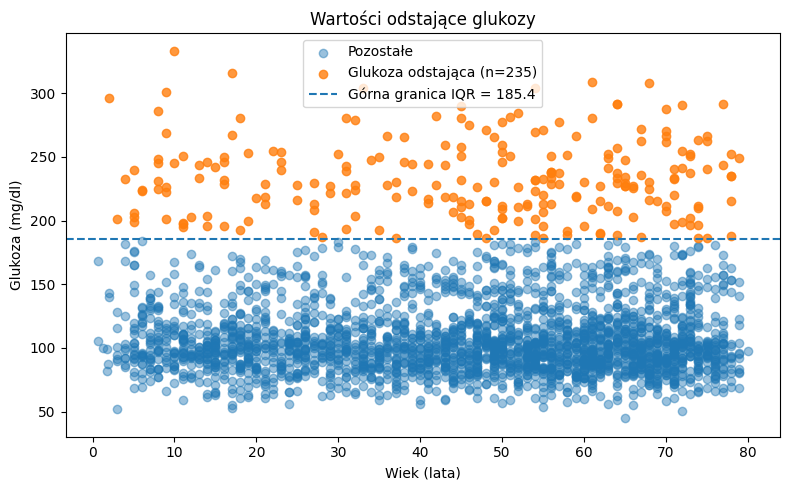

Liczba wartości powyżej górnej granicy: 235


In [31]:
# TODO: wykres punktowy z zaznaczonymi wartościami odstającymi
s = pacjenci["avg_glucose_level"]
q1, q3 = s.quantile([0.25, 0.75])
granica = q3 + 1.5 * (q3 - q1)
odst = maska_iqr(s, 1.5)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(pacjenci.loc[~odst, "age"], s[~odst], alpha=0.45, label="Pozostałe")
ax.scatter(pacjenci.loc[odst, "age"], s[odst], alpha=0.8, label=f"Glukoza odstająca (n={int(odst.sum())})")
ax.axhline(granica, linestyle="--", label=f"Górna granica IQR = {granica:.1f}")
ax.set_xlabel("Wiek (lata)")
ax.set_ylabel("Glukoza (mg/dl)")
ax.set_title("Wartości odstające glukozy")
ax.legend()
plt.tight_layout()
plt.show()
print("Liczba wartości powyżej górnej granicy:", int((s > granica).sum()))


### Czy wartość odstająca niesie informację?

Wysoki poziom glukozy może być związany z udarem. Porównaj odsetek udarów (`stroke`) wśród pacjentów z glukozą odstającą (IQR 1,5) i wśród pozostałych. Narysuj wykres pudełkowy glukozy w podziale na `stroke`.

Odsetek udarów wśród osób z odstającą glukozą: 0.2170212765957447
Odsetek udarów wśród pozostałych: 0.21916817359855334


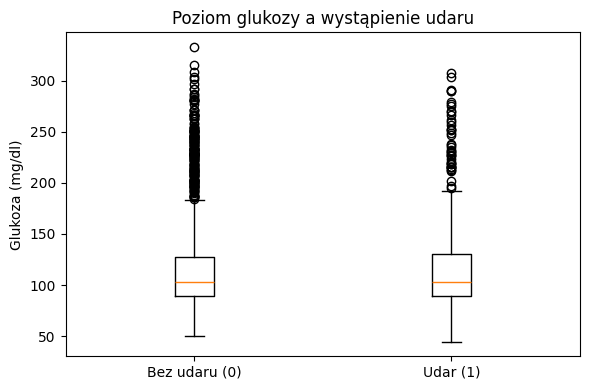

In [34]:
# TODO: odsetek udarów w obu grupach
odst_glukoza = maska_iqr(pacjenci["avg_glucose_level"], 1.5)
print("Odsetek udarów wśród osób z odstającą glukozą:",
      pacjenci.loc[odst_glukoza, "stroke"].mean())
print("Odsetek udarów wśród pozostałych:",
      pacjenci.loc[~odst_glukoza, "stroke"].mean())

# TODO: boxplot glukozy w podziale na stroke
fig, ax = plt.subplots(figsize=(6, 4))
grupy = [pacjenci.loc[pacjenci["stroke"] == 0, "avg_glucose_level"].dropna(),
         pacjenci.loc[pacjenci["stroke"] == 1, "avg_glucose_level"].dropna()]
ax.boxplot(grupy, tick_labels=["Bez udaru (0)", "Udar (1)"])
ax.set_ylabel("Glukoza (mg/dl)")
ax.set_title("Poziom glukozy a wystąpienie udaru")
plt.tight_layout()
plt.show()

✍️ **Pytanie:** Czy pacjentów z wysoką glukozą należy usunąć z danych, jeśli chcemy przewidywać udar?

*Odpowiedź:*

Nie należy usuwać pacjentów z wysoką glukozą, ponieważ może ona zawierać ważną informację związaną z przewidywanym udarem.

## 2.4 Krok 3: nielogiczne kombinacje kategorii

Każda wartość osobno może być poprawna („dziecko”, „pali”), a niemożliwa jest dopiero ich kombinacja.

1. Zrób tabelę krzyżową `work_type` × `smoking_status` (`pd.crosstab`). Co jest podejrzane?
2. Utwórz maski:
   - `dziecko_pali` — `work_type == "children"` i `smoking_status` to `"smokes"` lub `"formerly smoked"`,
   - `maluch_student` — wiek ≤ 3 lata i `work_type == "student"`.
3. Wyświetl znalezionych pacjentów.

In [37]:
# TODO: tabela krzyżowa
display(pd.crosstab(oryginal["work_type"], oryginal["smoking_status"]))

# TODO: maski
dziecko_pali = (oryginal["work_type"].eq("children") &
                 oryginal["smoking_status"].isin(["smokes", "formerly smoked"]))
maluch_student = (oryginal["age"].le(3) & oryginal["work_type"].eq("student"))
print("Dzieci palące / byłe palaczki:", int(dziecko_pali.sum()))
display(oryginal.loc[dziecko_pali])
print("Dzieci do 3 lat ze statusem student:", int(maluch_student.sum()))
display(oryginal.loc[maluch_student])


smoking_status,Unknown,formerly smoked,never smoked,smokes
work_type,,,,
Govt_job,16,63,94,67
Never_worked,1,30,36,35
Private,76,440,585,445
Self-employed,18,137,166,131
children,17,0,274,15
student,22,67,190,75


Dzieci palące / byłe palaczki: 15


,patient_id,gender,age,hypertension,heart_disease,ever_married,work_type,residence_type,avg_glucose_level,bmi,smoking_status,stroke
111,A678646,Female,9.00,0,0,False,children,Rural,96.59,22.24,smokes,0
290,A844121,Male,13.00,0,0,False,children,Urban,163.31,20.14,smokes,0
336,A135365,Female,12.00,0,0,False,children,Urban,135.59,27.15,smokes,0
352,A810636,Male,14.00,0,0,False,children,Rural,203.26,0.00,smokes,0
361,A843508,Male,2.00,0,0,False,children,Urban,143.14,39.11,smokes,0
578,A161666,Male,3.00,0,0,False,children,Urban,0.00,15.47,smokes,0
600,A623587,Male,10.00,0,0,False,children,Urban,5.00,20.93,smokes,0
613,A892803,Male,13.00,0,0,False,children,Urban,132.17,25.04,smokes,0
741,A560170,Male,13.00,0,0,False,children,Urban,243.95,25.59,smokes,0
767,A390530,Male,13.00,0,0,False,children,Urban,91.28,28.47,smokes,0


Dzieci do 3 lat ze statusem student: 1


,patient_id,gender,age,hypertension,heart_disease,ever_married,work_type,residence_type,avg_glucose_level,bmi,smoking_status,stroke
52,A582477,Female,1.80,0,0,False,student,Rural,82.20,24.05,formerly smoked,0


✍️ **Pytanie:** Czy IQR albo z-score mogłyby wykryć te przypadki? Dlaczego?

*Odpowiedź:*

Nie ponieważ analizują pojedyncze kolumny, nie logiczne zależności między kategoriami. Wartości mogą mieścić się w typowych wartościach mimo podejrzanych kombinacji.

## 2.5 Krok 4: nietypowe kombinacje liczb — odległość od środka

Liczymy kwadrat **odległości euklidesowej** każdego pacjenta od środka danych, po standaryzacji cech:

$$d^2 = \sum_j \left(\frac{x_j - \bar{x}_j}{s_j}\right)^2$$

Dla danych o rozkładzie normalnym $d^2$ ma rozkład $\chi^2$ z $p$ stopniami swobody ($p$ = liczba cech), więc próg bierzemy z kwantyla 0,99.

1. Weź kolumny `LICZBOWE` bez braków (`dropna`) → `X`.
2. Wystandaryzuj je i policz `d2`.
3. Wyznacz próg `chi2.ppf(0.99, df=3)` i policz, ilu pacjentów go przekracza.
4. Sprawdź, **która cecha** ma największy udział w $d^2$ u tych pacjentów (`idxmax(axis=1)` na kwadratach z-score'ów).

In [38]:
from scipy.stats import chi2

# TODO
X = pacjenci[LICZBOWE].dropna()
Z = (X - X.mean()) / X.std()
d2 = (Z ** 2).sum(axis=1)
prog = chi2.ppf(0.99, df=len(LICZBOWE))
odlegly = d2 > prog
print("Próg chi-kwadrat:", prog)
print("Liczba obserwacji odstających:", int(odlegly.sum()))
print("Cecha o największym udziale w d²:")
print((Z.loc[odlegly] ** 2).idxmax(axis=1).value_counts())

Próg chi-kwadrat: 11.344866730144373
Liczba obserwacji odstających: 73
Cecha o największym udziale w d²:
avg_glucose_level    54
bmi                  19
Name: count, dtype: int64


Glukoza jest silnie prawoskośna, więc odległość wskazuje głównie jej długi ogon. Powtórz obliczenia po zlogarytmowaniu glukozy (`np.log`) i porównaj liczbę odstających. Narysuj wykres punktowy `bmi` × `avg_glucose_level`, zaznaczając pacjentów odstających po transformacji.

Odstające przed logarytmowaniem: 73
Odstające po logarytmowaniu: 31


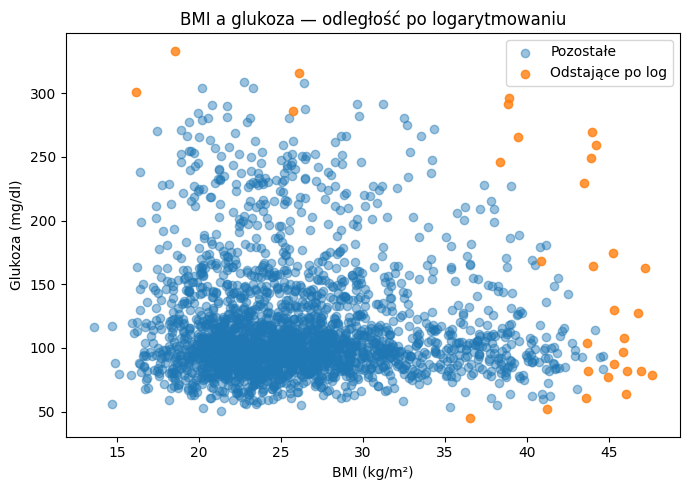

In [39]:
# TODO: X_log, Z_log, d2_log i liczba odstających
X_log = X.copy()
X_log["avg_glucose_level"] = np.log(X_log["avg_glucose_level"])
Z_log = (X_log - X_log.mean()) / X_log.std()
d2_log = (Z_log ** 2).sum(axis=1)
odlegly_log = d2_log > chi2.ppf(0.99, df=X_log.shape[1])
print("Odstające przed logarytmowaniem:", int(odlegly.sum()))
print("Odstające po logarytmowaniu:", int(odlegly_log.sum()))

# TODO: wykres punktowy
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(X_log.loc[~odlegly_log, "bmi"],
           np.exp(X_log.loc[~odlegly_log, "avg_glucose_level"]),
           alpha=0.45, label="Pozostałe")
ax.scatter(X_log.loc[odlegly_log, "bmi"],
           np.exp(X_log.loc[odlegly_log, "avg_glucose_level"]),
           alpha=0.8, label="Odstające po log")
ax.set_xlabel("BMI (kg/m²)")
ax.set_ylabel("Glukoza (mg/dl)")
ax.set_title("BMI a glukoza — odległość po logarytmowaniu")
ax.legend()
plt.tight_layout()
plt.show()

✍️ **Pytanie:** Wiek, BMI i glukoza są tu prawie nieskorelowane (sprawdź `X.corr()`). Czy w takiej sytuacji odległość Mahalanobisa dałaby coś więcej niż euklidesowa?

*Odpowiedź:*

Gdy cechy są prawie nieskolerowane, odległość Mahalanobisa zwykle nie wniesie dużej różnicy względem standaryzowanej odległości euklidesowej. Jest lebsza gdy trzeba uwzględnić korelacje między cechami.

### Dla chętnych: Isolation Forest

Użyj `sklearn.ensemble.IsolationForest` (`contamination=0.01`, `random_state=0`) na `X_log`. Ilu pacjentów wskazuje jednocześnie Isolation Forest i odległość `d2_log`?

In [40]:
# TODO (dla chętnych)
from sklearn.ensemble import IsolationForest

iso = IsolationForest(contamination=0.01, random_state=0)
wynik_iso = iso.fit_predict(X_log)
maska_iso = pd.Series(wynik_iso == -1, index=X_log.index)
print("Isolation Forest:", int(maska_iso.sum()))
print("Wspólne wskazania Isolation Forest i odległości d²:",
      int((maska_iso & odlegly_log).sum()))


Isolation Forest: 25
Wspólne wskazania Isolation Forest i odległości d²: 19


## 2.6 Krok 5: podsumowanie i decyzja

Zbierz wyniki wszystkich kroków w jednej ramce `flagi` (jeden wiersz na pacjenta, indeks jak w `oryginal`) z kolumnami logicznymi:

- `niemozliwa_wartosc` (krok 1),
- `glukoza_iqr` (krok 2, IQR 1,5 dla glukozy),
- `nielogiczna_kategoria` (krok 3),
- `odlegly_od_srodka` (krok 4, `d2_log`; pacjenci bez obliczonej odległości → `False`).

Policz, ilu pacjentów ma każdą flagę i ilu ma co najmniej jedną.

In [41]:
# TODO: ramka flagi
niemozliwe = zle_bmi | zla_glukoza | zly_wiek
nielogiczne = dziecko_pali | maluch_student
flagi = pd.DataFrame(index=oryginal.index)
flagi["niemozliwa_wartosc"] = niemozliwe.reindex(oryginal.index, fill_value=False)
flagi["glukoza_iqr"] = maska_iqr(pacjenci["avg_glucose_level"], 1.5).reindex(oryginal.index, fill_value=False)
flagi["nielogiczna_kategoria"] = nielogiczne.reindex(oryginal.index, fill_value=False)
flagi["odlegly_od_srodka"] = d2_log.gt(chi2.ppf(0.99, df=3)).reindex(oryginal.index, fill_value=False)
display(flagi.sum())
print("Pacjenci z co najmniej jedną flagą:", int(flagi.any(axis=1).sum()))
flagi

,0
niemozliwa_wartosc,560
glukoza_iqr,235
nielogiczna_kategoria,16
odlegly_od_srodka,31


Pacjenci z co najmniej jedną flagą: 806


,niemozliwa_wartosc,glukoza_iqr,nielogiczna_kategoria,odlegly_od_srodka
0,False,False,False,False
1,False,False,False,False
2,False,False,False,False
3,False,False,False,False
4,False,False,False,False
...,...,...,...,...
2995,False,False,False,False
2996,False,False,False,False
2997,False,False,False,False
2998,False,False,False,False


✍️ **Decyzja:** dla każdej grupy zaproponuj strategię i uzasadnij ją jednym zdaniem.

| Grupa | Strategia (poprawić / NaN / usunąć / przyciąć / log / zostawić / flaga) | Uzasadnienie |
|---|---|---|
| wartości niemożliwe | NaN | wartości spoza zakresów traktujemy jak błędy ale nie usuwamy rekordu |
| wysoka glukoza (IQR) | flaga/log | wysoka glukoza może mieć znaczenie dla przewidywania udaru |
| nielogiczne kategorie | poprawić/flaga | kombinacje sprzeczne należy poprawić jeżeli istnieją wiarygodne informacje |
| odlegli od środka | zostawić/flaga | wielowymiarowa nietypowość nie dowodzi błędu |